# 03 · Anomaly detection: catching fraud without labels

Notebook 02 assumed we know which past transactions were fraud. In practice labels are
**late** (chargebacks arrive weeks later), **incomplete** (undetected fraud is labelled
legit) and **scarce** for new fraud patterns. Anomaly detection drops the labels and
asks a different question: *how unusual is this transaction?*

Three set-ups, from least to most label information:

| Set-up | Trains on | Methods here |
|---|---|---|
| **Unsupervised** | all transactions, labels unknown | Isolation Forest, Mahalanobis distance |
| **Semi-supervised / novelty** | transactions known to be legit | Local Outlier Factor, autoencoder |
| **Supervised** (reference) | labelled fraud and legit | LightGBM from notebook 02 |

The bet behind anomaly detection is that fraud is *rare and different*. Notebook 01
suggested that holds for most frauds (they form their own clusters) but not all (≈ 7 %
hide among legit transactions). Let's measure how far the bet gets us.

In [1]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

from fraudkit.data import load_ulb, time_split
from fraudkit.metrics import bootstrap_ci, recall_at_alert_rate
from fraudkit.plotting import (
    CLASS_COLORS, INK_2, MUTED, SERIES, class_hist, class_legend, finish, label_bars, set_style,
)

set_style()
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
SEED = 42
ALERT_RATE = 0.005

df = load_ulb()
FEATURES = [f"V{i}" for i in range(1, 29)] + ["LogAmount", "Hour"]
train, val, test = time_split(df)
y_tr, y_va = train.Class.values, val.Class.values

# Distance-based methods need comparable scales; fit the scaler on training data only.
scaler = StandardScaler().fit(train[FEATURES])
Z_tr, Z_va = scaler.transform(train[FEATURES]), scaler.transform(val[FEATURES])
Z_legit = Z_tr[y_tr == 0]   # for the novelty methods: "known good" history

scores = {}

## 1. Isolation Forest (unsupervised)

**Idea.** Build random trees that split on a random feature at a random value. An
anomaly is *easy to isolate*: it ends up alone in a leaf after only a few splits, while a
normal point deep inside a dense cluster needs many. The anomaly score is the average path
length to isolate a point, shorter meaning more anomalous.

It trains on **all** training transactions, frauds included, without being told which
are which. That is the honest unsupervised setting: the frauds are just 0.2 % of the
data.

In [2]:
iso = IsolationForest(n_estimators=300, max_samples=1024, random_state=SEED, n_jobs=8).fit(Z_tr)
scores["Isolation Forest"] = -iso.score_samples(Z_va)   # flip sign: higher = more anomalous

## 2. Mahalanobis distance (unsupervised)

**Idea.** Model "normal" as a single multivariate Gaussian blob and score each point by
how many standard deviations it sits from the centre, accounting for correlations. For
PCA components, which are uncorrelated, this reduces to the sum of squared standardised
values. It is the simplest possible anomaly score and a useful sanity baseline.

In [3]:
cov = np.cov(Z_tr, rowvar=False)
inv_cov = np.linalg.inv(cov)
centered = Z_va - Z_tr.mean(axis=0)
scores["Mahalanobis"] = np.einsum("ij,jk,ik->i", centered, inv_cov, centered)

## 3. Local Outlier Factor (novelty detection on legit history)

**Idea.** Compare each point's local density with that of its *k* nearest neighbours. A
point in a sparse spot next to a dense cluster gets a high LOF. Unlike a global distance,
this adapts to clusters of different density.

With `novelty=True` we fit on legit transactions only and score new ones against that
reference. LOF compares every point with its neighbours, so we fit on a 40,000-row sample
of legit history to keep it fast.

In [4]:
rng = np.random.default_rng(SEED)
ref = Z_legit[rng.choice(len(Z_legit), 40_000, replace=False)]
lof = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=8).fit(ref)
scores["LOF (legit-only)"] = -lof.score_samples(Z_va)

## 4. Autoencoder (novelty detection on legit history)

**Idea.** Train a neural network to *copy its input to its output through a narrow
bottleneck* (30 → 20 → 8 → 20 → 30). To succeed it must learn a compressed description
of what legit transactions look like. A transaction unlike anything it trained on is
reconstructed badly, and the **reconstruction error** becomes the anomaly score.

scikit-learn's `MLPRegressor` with the input as its own target is an autoencoder. Early
stopping holds out 10 % of the legit data to decide when to stop training.

In [5]:
ae_train = Z_legit[rng.choice(len(Z_legit), 80_000, replace=False)]
ae = MLPRegressor(hidden_layer_sizes=(20, 8, 20), activation="tanh", alpha=1e-4,
                  batch_size=512, learning_rate_init=1e-3, max_iter=200,
                  early_stopping=True, n_iter_no_change=5, random_state=SEED)
ae.fit(ae_train, ae_train)
scores["Autoencoder (legit-only)"] = ((ae.predict(Z_va) - Z_va) ** 2).mean(axis=1)
print(f"autoencoder trained for {ae.n_iter_} epochs (cap: {ae.max_iter}; validation loss still creeping down)")

autoencoder trained for 200 epochs (cap: 200; validation loss still creeping down)


## 5. Supervised reference

The best model from notebook 02, retrained the same way, for comparison.

In [6]:
LGB_PARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                  random_state=SEED, verbose=-1, n_jobs=8)
sup = lgb.LGBMClassifier(**LGB_PARAMS).fit(train[FEATURES], y_tr)
scores["LightGBM (supervised)"] = sup.predict_proba(val[FEATURES])[:, 1]

## 6. How the scores separate the classes

Each panel shows a method's validation scores by class, on a log scale and normalised
within each class. The less the orange and blue overlap, the better.

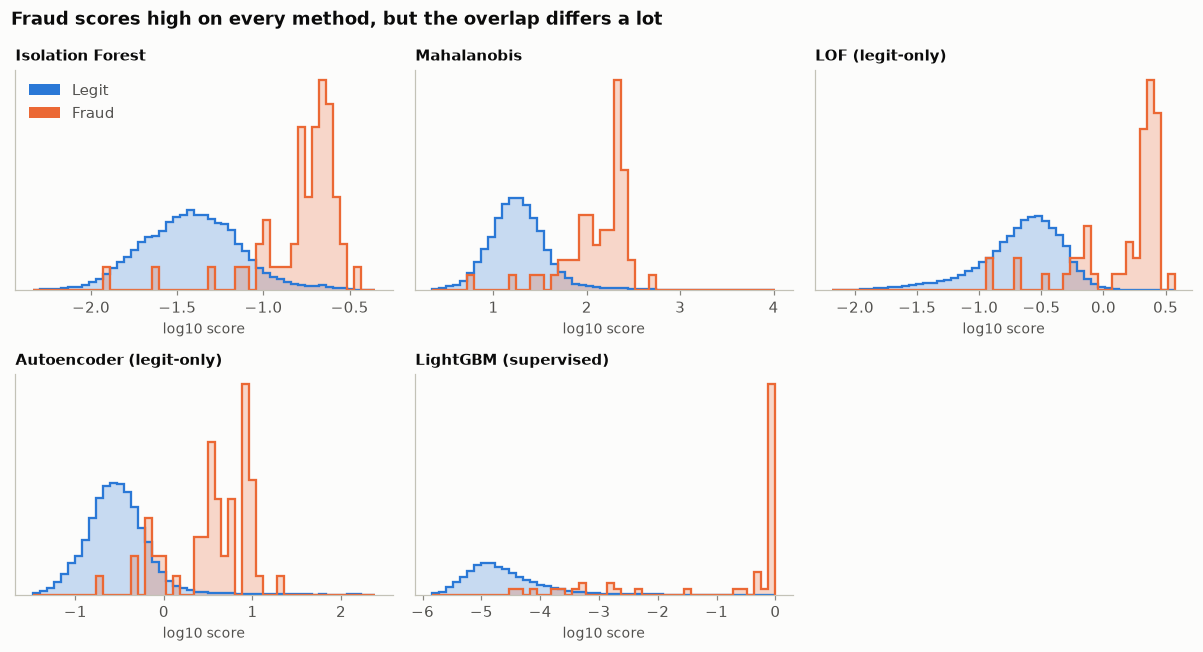

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, (name, s) in zip(axes.flat, scores.items()):
    v = np.log10(s - s.min() + 1e-6)   # shift to positive, then log, so tails are visible
    lo, hi = np.quantile(v, [0.001, 1])
    class_hist(ax, v, y_va, np.linspace(lo, hi, 50))
    ax.set_title(name, fontsize=10)
    ax.set_yticks([]); ax.grid(False)
    ax.set_xlabel("log10 score", fontsize=9)
axes.flat[-1].axis("off")
class_legend(axes.flat[0], loc="upper left")
fig.suptitle("Fraud scores high on every method, but the overlap differs a lot",
             x=0.01, ha="left", fontweight="bold")
finish(fig)

## 7. Head-to-head on the validation period

In [8]:
rows = {}
for name, s in scores.items():
    pr, lo, hi = bootstrap_ci(average_precision_score, y_va, s, n_boot=500)
    rows[name] = {"pr_auc": pr, "pr_auc_lo": lo, "pr_auc_hi": hi,
                  "recall@0.5%": recall_at_alert_rate(y_va, s, ALERT_RATE),
                  "recall@2%": recall_at_alert_rate(y_va, s, 0.02)}
res = pd.DataFrame(rows).T.sort_values("pr_auc", ascending=False)
res

,pr_auc,pr_auc_lo,pr_auc_hi,recall@0.5%,recall@2%
LightGBM (supervised),0.780,0.681,0.875,0.807,0.860
LOF (legit-only),0.387,0.269,0.525,0.737,0.772
Autoencoder (legit-only),0.041,0.029,0.058,0.333,0.789
Isolation Forest,0.027,0.019,0.040,0.088,0.667
Mahalanobis,0.021,0.015,0.028,0.018,0.579


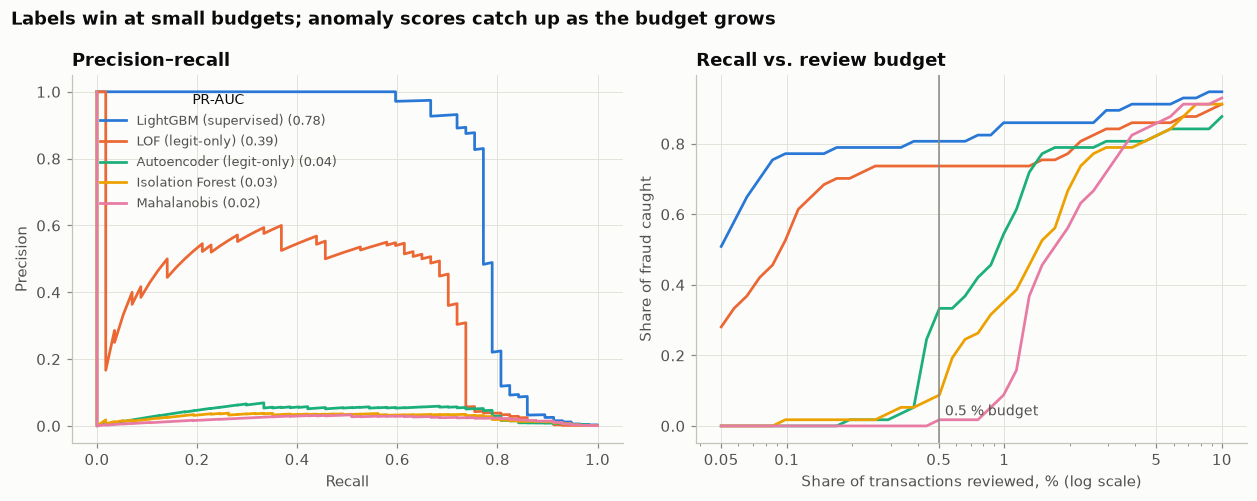

In [9]:
order = list(res.index)
colors = dict(zip(order, SERIES))   # fixed slot per method, reused in every chart below

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax = axes[0]
for name in order:
    p, r, _ = precision_recall_curve(y_va, scores[name])
    ax.plot(r, p, color=colors[name], lw=1.8, label=f"{name} ({res.loc[name, 'pr_auc']:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision–recall")
ax.legend(loc="lower left", bbox_to_anchor=(0.03, 0.6), fontsize=8.5, title="PR-AUC", title_fontsize=9)

ax = axes[1]
rates = np.geomspace(0.0005, 0.1, 40)
for name in order:
    ax.plot(rates * 100, [recall_at_alert_rate(y_va, scores[name], a) for a in rates],
            color=colors[name], lw=1.8)
ax.axvline(ALERT_RATE * 100, color=MUTED, lw=1)
ax.annotate("0.5 % budget", (ALERT_RATE * 100, 0.03), xytext=(4, 0), textcoords="offset points",
            color=INK_2, fontsize=9)
ax.set_xscale("log")
ax.set_xticks([0.05, 0.1, 0.5, 1, 5, 10], ["0.05", "0.1", "0.5", "1", "5", "10"])
ax.set_xlabel("Share of transactions reviewed, % (log scale)")
ax.set_ylabel("Share of fraud caught")
ax.set_title("Recall vs. review budget")
fig.suptitle("Labels win at small budgets; anomaly scores catch up as the budget grows",
             x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.**
* **The supervised model dominates at small review budgets.** It knows what fraud looks
  like, not just what "unusual" looks like.
* **LOF is in a different league from the other anomaly detectors.** Trained on legit
  history only, it catches ~74 % of fraud at the 0.5 % budget. It is local: it asks "is
  this point in a sparse spot *compared with its neighbours*?", which suits the many small
  fraud clusters seen in notebook 01.
* **The global methods show a striking pattern.** Isolation Forest, Mahalanobis and the
  autoencoder have near-zero precision at the very top of their ranking (PR-AUC ≈ 0.03),
  yet catch 58–79 % of fraud once 2 % of transactions are reviewed. The *most* extreme
  0.1 % of transactions are legit outliers: huge amounts, rare combinations. Fraud is
  "moderately unusual", which is precisely where they rank it.
* **PR-AUC and recall-at-budget tell different stories.** A team that can review 2–5 %
  of transactions would rate these detectors far higher than PR-AUC suggests. Always pick
  the metric that matches how alerts are actually worked.

## 8. Do they catch the *same* frauds?

If the anomaly detectors only find the frauds LightGBM already catches, they add nothing.
At the 0.5 % budget we check, fraud by fraud, which of the two families flags it. The
unsupervised family here is the best anomaly score from the table above.

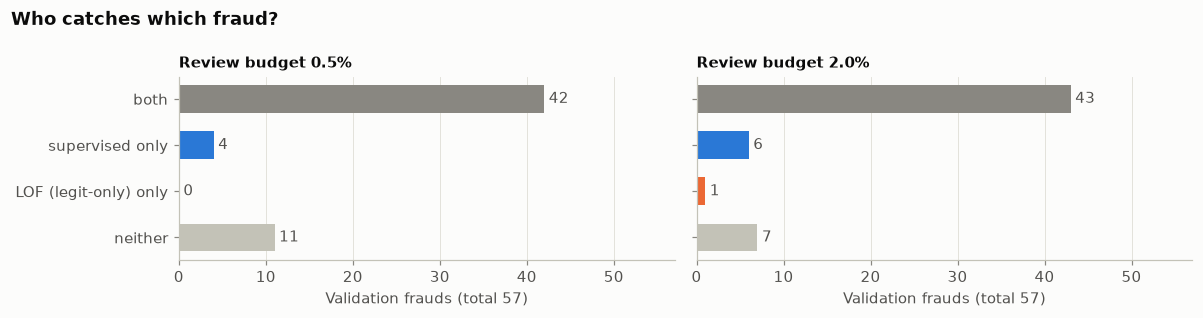

In [10]:
best_unsup = next(n for n in order if n != "LightGBM (supervised)")


def flagged(s, rate=ALERT_RATE):
    return s >= np.quantile(s, 1 - rate)


bar_colors = {"both": MUTED, "supervised only": colors["LightGBM (supervised)"],
              f"{best_unsup} only": colors[best_unsup], "neither": "#c3c2b7"}
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
for ax, rate in zip(axes, [ALERT_RATE, 0.02]):
    f_sup = flagged(scores["LightGBM (supervised)"], rate)[y_va == 1]
    f_uns = flagged(scores[best_unsup], rate)[y_va == 1]
    overlap = pd.Series({
        "both": (f_sup & f_uns).sum(),
        "supervised only": (f_sup & ~f_uns).sum(),
        f"{best_unsup} only": (~f_sup & f_uns).sum(),
        "neither": (~f_sup & ~f_uns).sum(),
    })[::-1]
    bars = ax.barh(overlap.index, overlap.values, height=0.6,
                   color=[bar_colors[n] for n in overlap.index])
    label_bars(ax, bars, fmt="{:.0f}", horizontal=True)
    ax.set_title(f"Review budget {rate:.1%}", fontsize=10)
    ax.set_xlim(0, y_va.sum())
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"Validation frauds (total {y_va.sum()})")
fig.suptitle("Who catches which fraud?", x=0.01, ha="left", fontweight="bold")
finish(fig)

**Reading it.** At either budget, the frauds LOF catches are almost all frauds LightGBM
catches too. The anomaly detector doesn't find a *different* kind of fraud here. The
"neither" group is the hard core seen in every notebook so far: frauds that look like
legit transactions in this feature space.

## 9. Hybrid: anomaly scores as features

The two families don't have to compete. A common production pattern feeds the anomaly
scores **into** the supervised model as extra features. The tree model can then learn
when "unusual" means fraud and when it doesn't.

To avoid leakage, the anomaly models are fitted on training data only (already the case)
and then used to score both periods.

In [11]:
def anomaly_features(Z):
    return np.column_stack([
        -iso.score_samples(Z),
        ((ae.predict(Z) - Z) ** 2).mean(axis=1),
    ])


X_tr_h = np.column_stack([train[FEATURES].values, anomaly_features(Z_tr)])
X_va_h = np.column_stack([val[FEATURES].values, anomaly_features(Z_va)])
hybrid = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr_h, y_tr)
scores["LightGBM + anomaly features"] = hybrid.predict_proba(X_va_h)[:, 1]

comparison = pd.DataFrame({
    n: dict(zip(["pr_auc", "lo", "hi"], bootstrap_ci(average_precision_score, y_va, scores[n], n_boot=500)))
    for n in ["LightGBM (supervised)", "LightGBM + anomaly features"]
}).T
comparison

,pr_auc,lo,hi
LightGBM (supervised),0.780,0.681,0.875
LightGBM + anomaly features,0.768,0.660,0.866


**Reading it.** No gain: the difference is far inside the bootstrap interval. That makes
sense given the overlap analysis. Anomaly scores are functions of the same 30 features,
and the trees already carve out the unusual regions that matter. A negative result is
still a result. Hybrids pay off when the anomaly model sees *information the supervised
model can't*, such as a customer's own history, which this dataset doesn't have.

## 10. How many labels do you need to beat "no labels"?

A question a fraud team actually faces: we have a few confirmed frauds, so is it time to
switch from anomaly detection to a supervised model? We simulate it by training LightGBM
with only *k* randomly chosen training frauds (all legit rows kept) and repeating each *k*
with 5 random draws.

In [12]:
ks = [5, 10, 20, 40, 80, 160, (y_tr == 1).sum()]
fraud_idx, legit_idx = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
curve = []
for k in ks:
    for rep in range(5 if k < len(fraud_idx) else 1):
        pick = np.random.default_rng(rep).choice(fraud_idx, k, replace=False)
        idx = np.r_[legit_idx, pick]
        m = lgb.LGBMClassifier(**LGB_PARAMS).fit(train[FEATURES].values[idx], y_tr[idx])
        curve.append({"k": k, "pr_auc": average_precision_score(y_va, m.predict_proba(val[FEATURES].values)[:, 1])})
curve = pd.DataFrame(curve)
agg = curve.groupby("k").pr_auc.agg(["mean", "min", "max"])
agg

,mean,min,max
k,,,
5,0.617,0.508,0.706
10,0.633,0.526,0.732
20,0.724,0.702,0.757
40,0.769,0.742,0.781
80,0.772,0.758,0.780
160,0.771,0.754,0.783
342,0.782,0.782,0.782


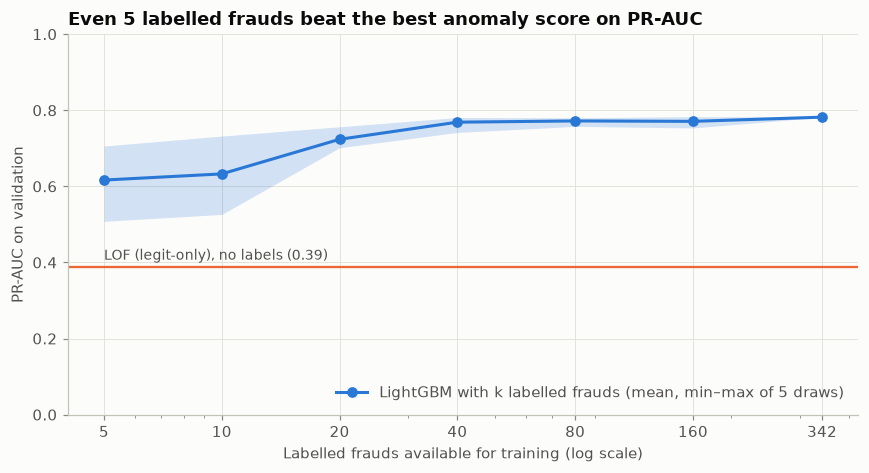

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.fill_between(agg.index, agg["min"], agg["max"], color=colors["LightGBM (supervised)"], alpha=0.2, lw=0)
ax.plot(agg.index, agg["mean"], marker="o", color=colors["LightGBM (supervised)"],
        label="LightGBM with k labelled frauds (mean, min–max of 5 draws)")
best_pr = res.loc[best_unsup, "pr_auc"]
ax.axhline(best_pr, color=colors[best_unsup], lw=1.5)
ax.annotate(f"{best_unsup}, no labels ({best_pr:.2f})", (agg.index[0], best_pr), xytext=(0, 5),
            textcoords="offset points", color=INK_2, fontsize=9)
ax.set_xscale("log")
ax.set_xticks(ks, [str(k) for k in ks])
ax.set_xlabel("Labelled frauds available for training (log scale)")
ax.set_ylabel("PR-AUC on validation")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
ax.set_title("Even 5 labelled frauds beat the best anomaly score on PR-AUC")
finish(fig)

**Reading it.** With only 5 labelled frauds, LightGBM already reaches a PR-AUC of ~0.6,
well above the best anomaly detector. About 40 frauds get it to within noise of the full
model; more labels add little on this dataset. The spread at small *k* shows the other
side: which 5 frauds you happen to have matters a lot.

## 11. Conclusions

* **Supervised beats unsupervised whenever labels exist, even a handful.** Five labelled
  frauds out-rank the best anomaly detector; forty match the full model.
* **Not all anomaly detectors are equal.** Local, novelty-style LOF (trained on legit
  history) caught ~74 % of fraud at a 0.5 % budget with no fraud labels. Global methods
  rank extreme legit transactions first and only become useful at 2 %+ budgets.
* **The metric changes the verdict.** By PR-AUC the global detectors look useless; by
  recall at a 2–5 % review budget they look respectable. Match the metric to the
  operating reality.
* **Here, anomaly scores add nothing on top of a supervised model.** The two families
  catch the same frauds, and the hybrid didn't improve. Anomaly detection's place is the
  cold start (new product, new market, before labels exist) and monitoring for *new* fraud
  patterns, not boosting a mature supervised model on the same features.

**Next:** [04 · Thresholds, costs and explainability](04_threshold_cost_explainability.ipynb)